# AI Applications & Mini Project 6 — Build, present, and discuss

**Digital Foundation for Chemical Engineers**  \n
Duration: 60 minutes

## Today’s goal
Create a compact evidence-based mini project from a supplied CSV and communicate its purpose, findings, limits, and responsible next step.

## 1. Project standard (8 min)
Your mini project should answer one useful question with visible evidence. It should contain: a clear stakeholder question; an imported CSV; at least one data check; one analysis or screening method; one chart/table; a conclusion; and a limitation.

A good conclusion describes what the data show. It does not claim that correlation proves cause or that a classroom analysis is ready for plant deployment.

In [ ]:
#pip install matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 30.1 MB/s  0:00:00m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 33.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 28.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 34.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [matplotlib]7 [matplotlib]

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [7]:
import pandas as pd
import matplotlib.pyplot as plt

project_data = pd.read_csv('data/equipment_sensor_120.csv')
project_data['timestamp'] = pd.to_datetime(project_data['timestamp'])
project_data.head()

,timestamp,pump_id,vibration_mm_s,bearing_temperature_c,motor_current_a,running_hours
0,2026-02-02 08:00:00,P-1,2.10,57.0,18.00,1000
1,2026-02-02 09:00:00,P-2,2.18,57.5,18.23,1006
2,2026-02-02 10:00:00,P-3,2.26,57.9,18.46,1012
3,2026-02-02 11:00:00,P-1,2.34,58.4,18.69,1018
4,2026-02-02 12:00:00,P-2,2.42,58.8,18.92,1024


## 2. Project workflow (12 min)
Follow this sequence: define the question; inspect columns and missing values; choose a transparent method; visualise evidence; write a bounded conclusion; state a human review action.

Suggested case question: Which pump readings should be prioritised for engineering review based on the supplied sensor data?

In [8]:
print(project_data.info())
print('Missing values:')
print(project_data.isna().sum())
display(project_data.groupby('pump_id')[['vibration_mm_s', 'bearing_temperature_c']].mean())

<class 'pandas.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 6 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   timestamp              120 non-null    datetime64[us]
 1   pump_id                120 non-null    str           
 2   vibration_mm_s         120 non-null    float64       
 3   bearing_temperature_c  120 non-null    float64       
 4   motor_current_a        120 non-null    float64       
 5   running_hours          120 non-null    int64         
dtypes: datetime64[us](1), float64(3), int64(1), str(1)
memory usage: 5.8 KB
None
Missing values:
timestamp                0
pump_id                  0
vibration_mm_s           0
bearing_temperature_c    0
motor_current_a          0
running_hours            0
dtype: int64


,vibration_mm_s,bearing_temperature_c
pump_id,,
P-1,2.4825,60.3875
P-2,2.5850,60.4025
P-3,2.6425,60.3900


## 3. Worked project scaffold (15 min)
This is a starting point, not a final answer. Adjust the question, data source, chart, and screening method for your pair’s chosen case.

Review readings: 32


,timestamp,pump_id,vibration_mm_s,bearing_temperature_c
9,2026-02-02 17:00:00,P-1,2.82,61.0
10,2026-02-02 18:00:00,P-2,2.90,61.5
11,2026-02-02 19:00:00,P-3,2.98,62.0
21,2026-02-03 05:00:00,P-1,2.82,59.2
22,2026-02-03 06:00:00,P-2,2.90,59.7
23,2026-02-03 07:00:00,P-3,2.98,60.1
33,2026-02-03 17:00:00,P-1,2.82,57.5
34,2026-02-03 18:00:00,P-2,2.90,57.9
35,2026-02-03 19:00:00,P-3,2.98,58.4
43,2026-02-04 03:00:00,P-2,3.56,66.0


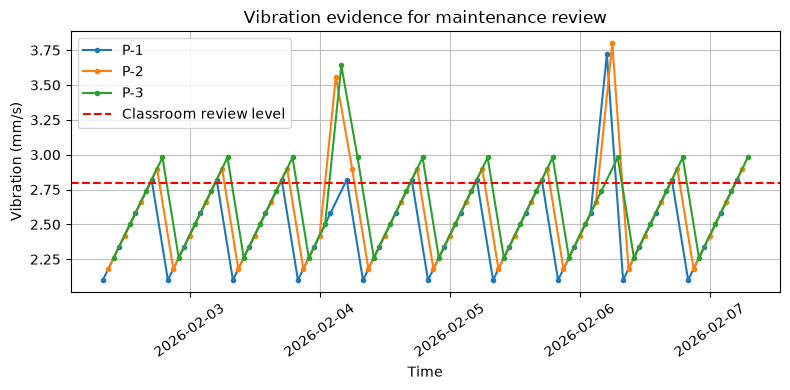

In [13]:
review = project_data[(project_data['vibration_mm_s'] >= 2.8) |
                      (project_data['bearing_temperature_c'] >= 65)].copy()
print('Review readings:', len(review))
display(review[['timestamp', 'pump_id', 'vibration_mm_s', 'bearing_temperature_c']])

plt.figure(figsize=(8, 4))
for pump_id, group in project_data.groupby('pump_id'):
    plt.plot(group['timestamp'], group['vibration_mm_s'], marker='.', label=pump_id)
plt.axhline(2.8, color='red', linestyle='--', label='Classroom review level')
plt.title('Vibration evidence for maintenance review')
plt.xlabel('Time')
plt.ylabel('Vibration (mm/s)')
plt.legend()
plt.grid(alpha=0.8)
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

## 4. Presentation structure (15 min)
Prepare a 3-minute presentation with five slides or sections:

1. Problem and stakeholder
2. CSV data and its limitations
3. Method and visible screening rule/analysis
4. Key chart/table and observation
5. Recommendation for human review and next step

Use units. Explain any threshold. Do not claim that the tool diagnoses a fault or makes a safety decision.

## Peer review and case discussion (10 min)
For each presentation, peers should ask: Is the question clear? Can the conclusion be traced to the data? Is a limitation stated? Is the recommended action proportionate?

**Challenge:** Propose what labelled history, validation method, and monitoring would be required before developing a predictive ML model.

## Module wrap-up
You have explored AI applications in maintenance, quality, safety, anomaly detection, and automation. The durable skill is not merely using a tool: it is asking a well-scoped question, checking data, making reasoning visible, and keeping human engineering judgement in control.